# Interpretación de los grupos

## Entorno

Importé las librerías y fijé la semilla 42, que usan la partición y todos los modelos. Sin semilla,
K-Means y GMM arrancan desde centroides o componentes distintos en cada corrida, así que los grupos, su
numeración y las métricas cambiarían, y nadie podría verificar las cifras del informe. También imprimí
las versiones de Python, NumPy, pandas, scikit-learn y Matplotlib, porque los valores por defecto de los
estimadores cambian de una versión a otra y con ellos los resultados.

Definí tres funciones auxiliares. La función redondear aplica redondeo mitad hacia arriba una sola vez
sobre el valor completo. La usé en todas las cifras que se guardan porque round de Python trabaja sobre
la representación binaria y, por ejemplo, redondea 0,2175 a 0,217, mientras que el informe diría 0,218.
Así cada número se ve igual en el notebook y en el informe. La función guardar escribe la figura en
splits antes de mostrarla, porque plt.show libera la figura y el archivo saldría en blanco. La función
guardar_resultados agrega las cifras de cada notebook a resultados.json, de donde las toma el informe sin
copiarlas a mano.

In [1]:
import os, time, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
from decimal import Decimal, ROUND_HALF_UP

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.dpi'] = 100
SEMILLA = 42
np.random.seed(SEMILLA)

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    if not os.path.isdir('/content/drive/MyDrive'):
        raise RuntimeError('Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso '
                           'en la ventana emergente.')
    RUTA = '/content/drive/MyDrive/credit_card'
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath('..' if os.path.basename(os.getcwd()) == 'notebooks' else '.')

CARPETA_SPLITS = os.path.join(RUTA, 'splits')
os.makedirs(CARPETA_SPLITS, exist_ok=True)
ARCHIVO_RESULTADOS = os.path.join(RUTA, 'resultados.json')
resultados = {}
if os.path.exists(ARCHIVO_RESULTADOS):
    with open(ARCHIVO_RESULTADOS, encoding='utf-8') as f:
        resultados = json.load(f)

def redondear(valor, decimales=3):
    r = Decimal(repr(float(valor))).quantize(Decimal(1).scaleb(-decimales), rounding=ROUND_HALF_UP)
    return int(r) if decimales == 0 else float(r)

def redondear_serie(serie, decimales=3):
    return serie.map(lambda v: redondear(v, decimales))

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_SPLITS, nombre + '.png'), dpi=150, bbox_inches='tight', facecolor='white')
    print('Gráfico guardado:', nombre + '.png')
    plt.show()

def guardar_resultados():
    with open(ARCHIVO_RESULTADOS, 'w', encoding='utf-8') as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1,
                  default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print('Cifras guardadas en resultados.json')

resultados['versiones'] = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                           'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
print('Guardando en Google Drive' if EN_DRIVE else 'Google Drive no disponible, guardando localmente')
print('Versiones:', resultados['versiones'])

Google Drive no disponible, guardando localmente
Versiones: {'python': '3.12.10', 'numpy': '2.2.6', 'pandas': '3.0.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.9'}


## Carga de los datos preparados

Cargué de datos_preparados.joblib lo que dejó el notebook 03, las particiones de entrenamiento y prueba
en unidades originales y transformadas, las listas de columnas y la marca de atípicos. Usar ese archivo
en lugar de repetir el preprocesamiento garantiza que el transformador sea exactamente el que se ajustó
con entrenamiento. También cargué las etiquetas de la etapa 1 y de la etapa 2.

In [2]:
prep = joblib.load(os.path.join(RUTA, 'datos_preparados.joblib'))
X_train, X_test, X_tr, X_te = prep['X_train'], prep['X_test'], prep['X_tr'], prep['X_te']
MONTOS, RESTO, COLUMNAS, frecuencias, fuera = prep['MONTOS'], prep['RESTO'], prep['COLUMNAS'], prep['frecuencias'], prep['fuera']
print('Entrenamiento:', X_tr.shape, '| Prueba:', X_te.shape)

e1 = joblib.load(os.path.join(RUTA, 'etapa1.joblib'))
K_KM, COV, REG, K_GMM = e1['K_KM'], e1['COV'], e1['REG'], e1['K_GMM']
et_km_tr, et_km_te, et_gm_tr, et_gm_te = e1['et_km_tr'], e1['et_km_te'], e1['et_gm_tr'], e1['et_gm_te']
print('Etapa 1, K-Means con K =', K_KM, '| GMM', COV, 'reg_covar', REG, 'K =', K_GMM)

e2 = joblib.load(os.path.join(RUTA, 'etapa2.joblib'))
K_KM_PCA, et_kmp_tr = e2['K_KM_PCA'], e2['et_kmp_tr']
print('Etapa 2, K-Means en PCA con K =', K_KM_PCA)

Entrenamiento: (7160, 17) | Prueba: (1790, 17)
Etapa 1, K-Means con K = 6 | GMM diag reg_covar 0.3 K = 4
Etapa 2, K-Means en PCA con K = 5


## Perfiles en unidades originales

Describí cada grupo con la mediana de las variables sin transformar, porque al banco le dice más un saldo
de 1 447 que un valor transformado. Usé la mediana porque resiste mejor que la media a los clientes
extremos. El mapa de calor, en cambio, usa la media transformada de cada grupo y muestra en qué se aleja
cada uno del cliente promedio. Empiezo por K-Means con 6 grupos en el espacio original, la configuración que recomiendo porque tuvo el mejor Silhouette en la comparación justa del notebook 05 y separa seis perfiles con acciones distintas.

Gráfico guardado: 06_perfil_kmeans.png


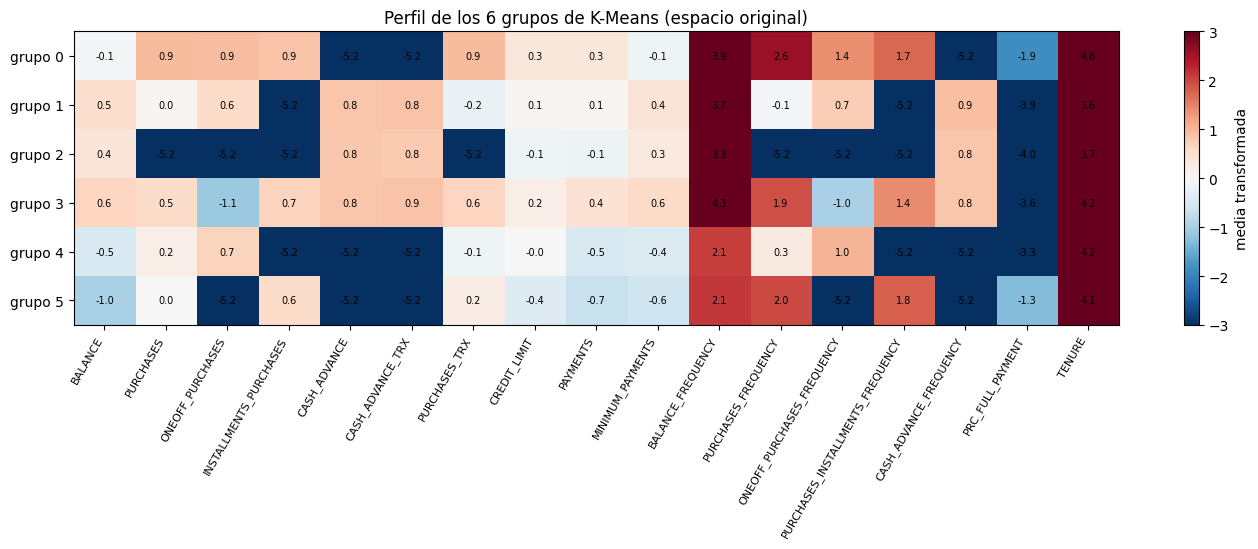

,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,1412,19.7,536,1535,773,534,0,0.92,0.00,5000,1327,0.0,12
1,646,9.0,1663,303,303,0,1176,0.17,0.25,3500,1076,0.0,12
2,1647,23.0,1447,0,0,0,1204,0.00,0.22,3000,772,0.0,12
3,1164,16.3,1878,795,231,407,1132,0.83,0.25,4125,1564,0.0,12
4,843,11.8,229,440,439,0,0,0.25,0.00,3000,576,0.0,12
5,1448,20.2,55,320,0,320,0,0.83,0.00,2500,417,0.1,12


In [3]:
CLAVE = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
         'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

def perfil(etiquetas):
    t = X_train.assign(grupo=etiquetas)
    p = t.groupby('grupo')[CLAVE].median()
    p = p.apply(lambda c: redondear_serie(c, 2 if 'FREQUENCY' in c.name or c.name == 'PRC_FULL_PAYMENT' else 0))
    p.insert(0, 'clientes', t['grupo'].value_counts().sort_index())
    p.insert(1, 'por ciento', redondear_serie(p['clientes'] / len(t) * 100, 1))
    return p

def mapa(etiquetas, nombre, titulo):
    z = pd.DataFrame(X_tr, columns=COLUMNAS).groupby(etiquetas).mean()
    fig, ax = plt.subplots(figsize=(14, 0.6 * len(z) + 2))
    im = ax.imshow(z, cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto')
    ax.set_xticks(range(len(COLUMNAS)))
    ax.set_xticklabels(COLUMNAS, rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(z)))
    ax.set_yticklabels([f'grupo {i}' for i in z.index])
    for i in range(len(z)):
        for j in range(len(COLUMNAS)):
            ax.text(j, i, f'{z.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7)
    fig.colorbar(im, label='media transformada')
    ax.set_title(titulo)
    guardar(nombre)

perfil_km = perfil(et_km_tr)
resultados['perfil_km'] = perfil_km.to_dict(orient='index')
mapa(et_km_tr, '06_perfil_kmeans', f'Perfil de los {K_KM} grupos de K-Means (espacio original)')
perfil_km

Nombré los grupos de la configuración recomendada a partir de sus medianas en unidades originales y del
mapa de calor.

| Grupo | Clientes | Nombre | Rasgo principal | Acción del banco |
|---|---|---|---|---|
| 0 | 19,7 por ciento | Compradores premium | Los que más compran (1 535) y con más frecuencia (0,92), con el mayor límite (5 000) y sin efectivo | Tarjeta de categoría superior, programa de puntos y más límite |
| 1 | 9,0 por ciento | Efectivo con compras ocasionales | Retiran 1 176 en efectivo y compran poco en un solo pago (303, frecuencia 0,17), con saldo de 1 663 | Préstamo personal más barato que el avance y promociones para comprar con la tarjeta |
| 2 | 23,0 por ciento | Usuarios de efectivo | No compran, retiran 1 204 en efectivo y deben 1 447 | Vigilar la mora y ofrecer un préstamo personal más barato que el avance |
| 3 | 16,3 por ciento | Intensivos endeudados | Compran seguido (frecuencia 0,83) y además retiran 1 132 en efectivo, con el mayor saldo (1 878) | Refinanciar la deuda y no aumentar el límite |
| 4 | 11,8 por ciento | Compradores ocasionales | Compras de un solo pago cada tanto (440, frecuencia 0,25), saldo bajo y sin efectivo | Promociones de temporada y ofrecer pasar compras grandes a cuotas |
| 5 | 20,2 por ciento | Compradores en cuotas | Compran en cuotas y seguido (320, frecuencia 0,83), con saldo casi nulo (55) y sin efectivo | Campañas de cuotas sin interés con comercios aliados |

Antes de entrenar esperaba cuatro perfiles, cliente que paga el total, cliente endeudado que retira
efectivo, comprador en cuotas y cliente inactivo. Los datos confirmaron dos, el comprador en cuotas y el
cliente que retira efectivo. No apareció un grupo que pague el total, porque la proporción del pago total tuvo una mediana entre 0 y 0,1 en todos los grupos. Tampoco apareció un grupo de inactivos, y
el perfil más cercano fue el de compradores ocasionales, con saldo de 229 y frecuencia de compra de 0,25.
Surgieron en cambio segmentos que no había previsto. El cliente que retira efectivo se dividió en tres,
según si no compra, si compra poco o si compra seguido, y los compradores premium se
separaron de los ocasionales. Como el conjunto no tiene etiquetas de referencia, no calculé ARI ni NMI
externos.

Repetí la descripción con los cuatro grupos de GMM y con los cinco de K-Means en PCA, para ver cómo
agrupa cada configuración a los mismos clientes.

Gráfico guardado: 06_perfil_gmm.png


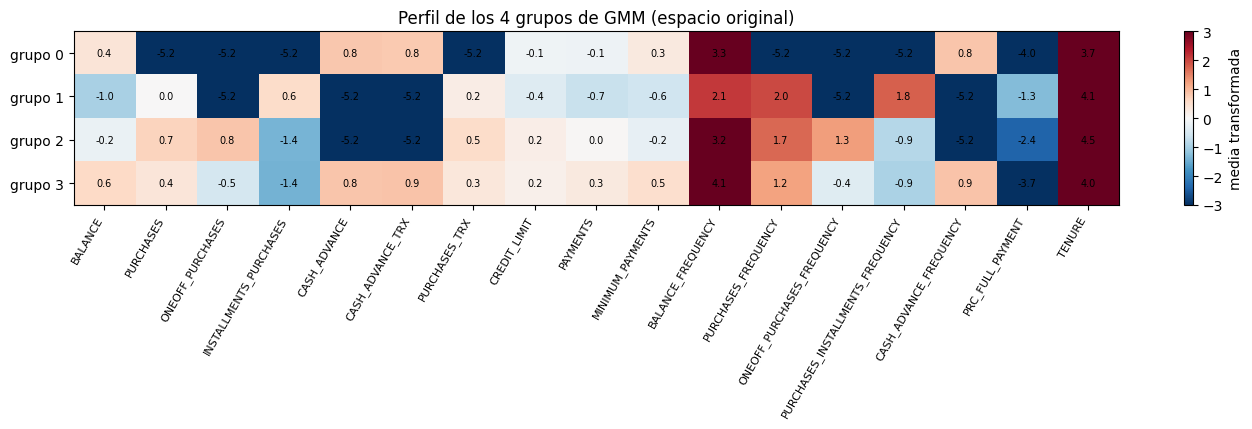

Gráfico guardado: 06_perfil_kmeans_pca.png


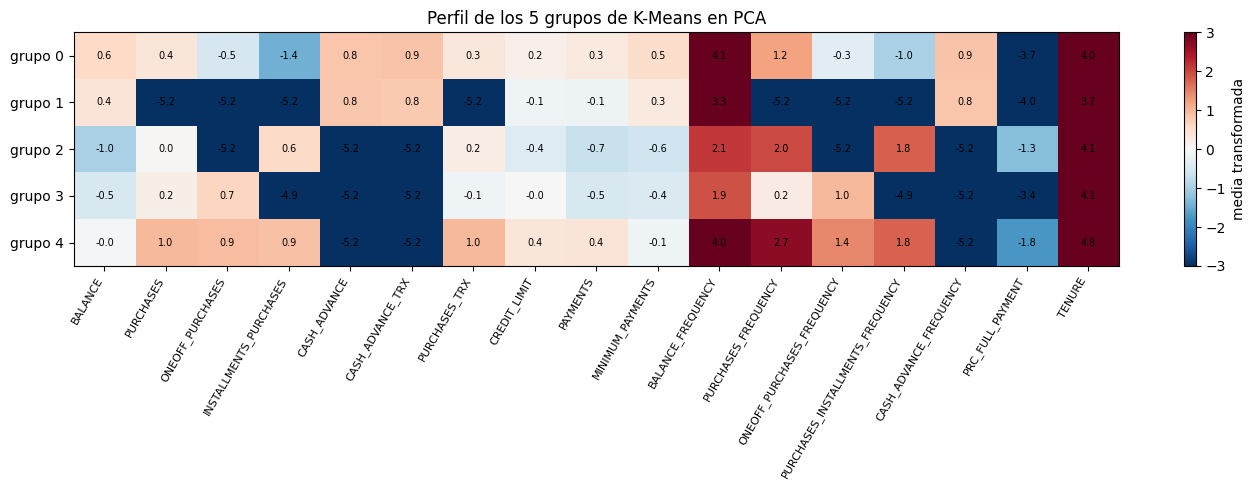

,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,1645,23.0,1447,0,0,0,1204,0.00,0.22,3000,772,0.0,12
1,1448,20.2,55,320,0,320,0,0.83,0.00,2500,417,0.1,12
2,2255,31.5,433,1003,624,185,0,0.75,0.00,4500,1035,0.0,12
3,1812,25.3,1778,578,263,158,1154,0.58,0.25,4000,1363,0.0,12


,clientes,por ciento,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,TENURE
grupo,,,,,,,,,,,,,
0,1803,25.2,1784,578,269,157,1157,0.58,0.25,4000,1362,0.0,12
1,1647,23.0,1447,0,0,0,1204,0.00,0.22,3000,772,0.0,12
2,1456,20.3,55,320,0,320,0,0.83,0.00,2500,417,0.1,12
3,885,12.4,212,440,431,0,0,0.25,0.00,3000,569,0.0,12
4,1369,19.1,554,1583,804,567,0,0.92,0.00,5000,1356,0.0,12


In [4]:
perfil_gm, perfil_kmp = perfil(et_gm_tr), perfil(et_kmp_tr)
resultados['perfil_gmm'] = perfil_gm.to_dict(orient='index')
resultados['perfil_km_pca'] = perfil_kmp.to_dict(orient='index')
mapa(et_gm_tr, '06_perfil_gmm', f'Perfil de los {K_GMM} grupos de GMM (espacio original)')
mapa(et_kmp_tr, '06_perfil_kmeans_pca', f'Perfil de los {K_KM_PCA} grupos de K-Means en PCA')
display(perfil_gm)
perfil_kmp

GMM llegó a los mismos perfiles con menos detalle. Sus cuatro grupos son los usuarios de efectivo (23,0
por ciento), los compradores en cuotas (20,2 por ciento), un grupo del 31,5 por ciento que junta a los
compradores premium con los ocasionales y otro del 25,3 por ciento con los clientes que compran y además
retiran efectivo. K-Means en PCA conservó cinco de los seis grupos del original y juntó a los dos
perfiles que combinan compras y efectivo en un grupo del 25,2 por ciento de los clientes. En los dos
casos se pierde una diferencia que le importa al banco, entre el comprador de alto gasto y el ocasional,
o entre el cliente que retira efectivo y compra seguido y el que retira efectivo y compra poco.

## Peso de cada grupo en el negocio

Calculé, para cada grupo de la configuración recomendada, qué parte del total de compras, de la deuda y
del efectivo retirado de la cartera de entrenamiento le corresponde, y la frecuencia media de compra y de
avances en efectivo. Un grupo puede tener pocos clientes y concentrar buena parte de la deuda, y ese
desbalance es el que dice dónde poner el esfuerzo comercial y dónde vigilar.

In [5]:
t = X_train.assign(grupo=et_km_tr)
totales = X_train[['PURCHASES', 'BALANCE', 'CASH_ADVANCE']].sum()
negocio = (t.groupby('grupo')[['PURCHASES', 'BALANCE', 'CASH_ADVANCE']].sum() / totales * 100)
negocio = negocio.apply(lambda c: redondear_serie(c, 1)).rename(columns={
    'PURCHASES': 'compras (por ciento)', 'BALANCE': 'deuda (por ciento)', 'CASH_ADVANCE': 'efectivo (por ciento)'})
negocio.insert(0, 'clientes (por ciento)', perfil_km['por ciento'])
frecuencias_medias = t.groupby('grupo')[['PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY']].mean()
negocio['frecuencia media de compra'] = redondear_serie(frecuencias_medias['PURCHASES_FREQUENCY'], 2)
negocio['frecuencia media de efectivo'] = redondear_serie(frecuencias_medias['CASH_ADVANCE_FREQUENCY'], 2)
resultados['negocio_km'] = negocio.to_dict(orient='index')
negocio

,clientes (por ciento),compras (por ciento),deuda (por ciento),efectivo (por ciento),frecuencia media de compra,frecuencia media de efectivo
grupo,,,,,,
0,19.7,50.0,15.6,0.0,0.81,0.00
1,9.0,6.3,13.6,19.0,0.28,0.29
2,23.0,0.0,31.9,46.6,0.00,0.27
3,16.3,23.2,28.3,34.4,0.74,0.28
4,11.8,9.8,5.7,0.0,0.35,0.00
5,20.2,10.7,4.9,0.0,0.71,0.00


Los grupos pesan muy distinto en el negocio. Los compradores premium son el 19,7 por ciento de los
clientes y concentran el 50,0 por ciento de las compras, la mitad de todo lo comprado con tarjeta. En el
otro extremo, los usuarios de efectivo son el 23,0 por ciento de los clientes y tienen el 31,9 por ciento
de la deuda y el 46,6 por ciento del efectivo retirado. Los intensivos endeudados, con el 16,3 por ciento
de los clientes, tienen el 28,3 por ciento de la deuda y el 34,4 por ciento del efectivo, y el grupo de
efectivo con compras ocasionales, con el 9,0 por ciento, tiene el 13,6 por ciento de la deuda y el 19,0
por ciento del efectivo. Los compradores en cuotas, con el 20,2 por ciento de los clientes, tienen solo
el 4,9 por ciento de la deuda. Para el banco eso significa que retener a los compradores premium sostiene
la mitad de la facturación con tarjeta, y que la vigilancia de mora tiene que concentrarse en los tres
grupos que retiran efectivo.

## Variables que definen la agrupación

Calculé el eta cuadrado de cada variable transformada, η² = SS_entre / SS_total. SS_total = Σ_i (x_i −
x̄)² es la variación total de la variable y SS_entre = Σ_k n_k (x̄_k − x̄)² la parte que explican las
medias de los grupos. Va de 0 a 1. Cerca de 1, la variable cambia mucho de un grupo a otro y casi nada
dentro de cada grupo, así que define la segmentación. Cerca de 0, no ayuda a separarlos. Lo calculé para
las particiones de K-Means en los dos espacios, siempre sobre las 17 variables transformadas, para que
los valores sean comparables.

Gráfico guardado: 06_eta_cuadrado.png


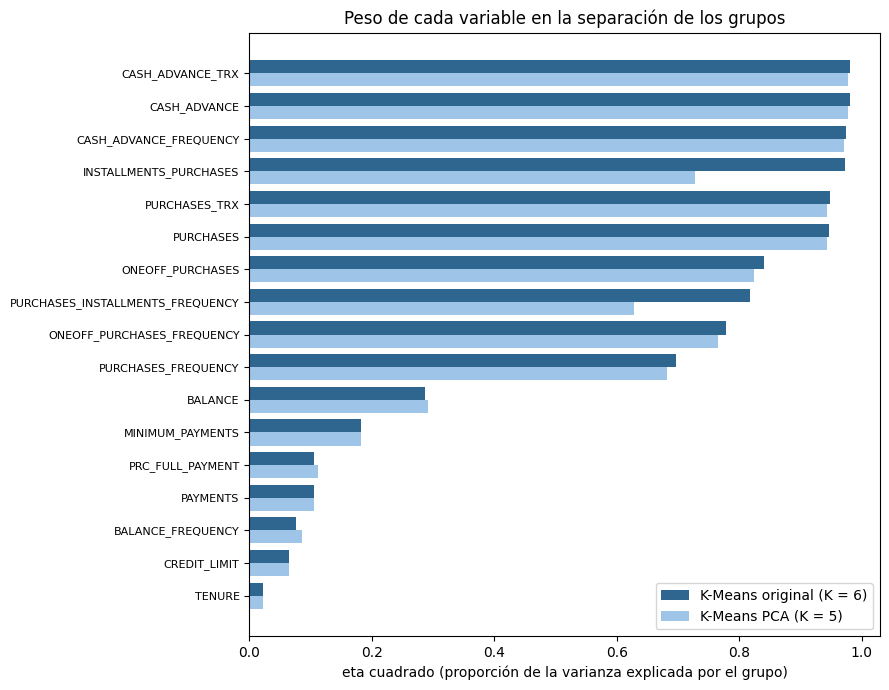

,K-Means original,K-Means PCA
CASH_ADVANCE_TRX,0.981,0.978
CASH_ADVANCE,0.981,0.978
CASH_ADVANCE_FREQUENCY,0.975,0.972
INSTALLMENTS_PURCHASES,0.973,0.728
PURCHASES_TRX,0.949,0.943
PURCHASES,0.946,0.944
ONEOFF_PURCHASES,0.840,0.824
PURCHASES_INSTALLMENTS_FREQUENCY,0.818,0.629
ONEOFF_PURCHASES_FREQUENCY,0.779,0.766
PURCHASES_FREQUENCY,0.697,0.682


In [6]:
def eta_cuadrado(etiquetas):
    Z = pd.DataFrame(X_tr, columns=COLUMNAS)
    total = ((Z - Z.mean()) ** 2).sum()
    medias = Z.groupby(etiquetas).transform('mean')
    entre = ((medias - Z.mean()) ** 2).sum()
    return redondear_serie(entre / total)

eta = pd.DataFrame({'K-Means original': eta_cuadrado(et_km_tr),
                    'K-Means PCA': eta_cuadrado(et_kmp_tr)}).sort_values('K-Means original')
resultados['eta_cuadrado'] = eta.to_dict()
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(eta))
ax.barh(y + 0.2, eta['K-Means original'], height=0.4, color='#2f6690', label=f'K-Means original (K = {K_KM})')
ax.barh(y - 0.2, eta['K-Means PCA'], height=0.4, color='#9ec5e8', label=f'K-Means PCA (K = {K_KM_PCA})')
ax.set_yticks(y)
ax.set_yticklabels(eta.index, fontsize=8)
ax.set_xlabel('eta cuadrado (proporción de la varianza explicada por el grupo)')
ax.set_title('Peso de cada variable en la separación de los grupos')
ax.legend()
guardar('06_eta_cuadrado')
eta.sort_values('K-Means original', ascending=False)

Los grupos quedaron definidos sobre todo por el uso del efectivo y de la compra. Las variables con más
peso en la partición recomendada fueron el monto y el número de avances en efectivo (eta cuadrado de
0,981 cada una), su frecuencia (0,975), las compras en cuotas (0,973), el número de compras (0,949) y el
monto comprado (0,946). En cambio la antigüedad (0,022), el límite de crédito (0,064), los pagos y la
proporción del pago total (0,106 cada una), el pago mínimo (0,182) y el saldo (0,287) casi no
cambian de un grupo a otro, y por eso no apareció un segmento de clientes que paguen el total. Las dos
particiones de K-Means dieron pesos parecidos, salvo en las compras en cuotas (0,973 en el original y
0,728 en PCA) y su frecuencia (0,818 y 0,629), que distinguían a los dos grupos que PCA fusionó.

En términos del negocio, el modelo responde dos preguntas sobre cada cliente, si usa la tarjeta para
comprar, para sacar efectivo o para las dos cosas, y si compra en cuotas o en un solo pago.

## Cierre del notebook

Guardé las cifras de este notebook en resultados.json.

In [7]:
guardar_resultados()

Cifras guardadas en resultados.json
